# 🌳 08 · Hierarchical Softmax

> **Module 03 – Text to Numbers and Word Embeddings** · Notebook 8 of 9
> Course notes: pages 18–20 – *"Hierarchical softmax: binary tree (Huffman), n leaves = words, n − 1 inner neurons"*, codes *left = 0, right = 1* (*w₁: 00, w₅: 10, w₄: 0111*), *"average path length O(log n)"*, *"p(word) = product along the path"*; inference by **greedy** (worst O(n), average O(log n)), **beam search** (keep the best k), **branch and bound** (exact, budget not controllable); the greedy-failure example $0.7\times0.6\times0.51$ vs $0.3\times0.99\times0.99$

Negative sampling (notebook 07) made training cheap but gave up a proper probability distribution. **Hierarchical softmax** keeps $\sum_wp(w\mid h)=1$ *and* is cheap: instead of one choice among $n$ words, the model makes a **sequence of left/right decisions** down a binary tree whose leaves are the words.

### 🎯 What you will learn
| # | Idea |
|---|---|
| 1 | Words as leaves of a binary tree; each inner node is a small logistic regression |
| 2 | $p(w\mid h)=$ product of left/right probabilities along the path – and why it sums to 1 |
| 3 | The **Huffman** tree: frequent words get short paths, average length $\approx$ entropy $\le\log_2n$ |
| 4 | The training update: only the $\approx\log_2n$ nodes on one path change |
| 5 | Finding the most likely word: greedy, beam search, branch and bound |

## 0 · Setup

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

# ---------- one consistent, clean plotting style for the whole notebook ----------
C = dict(blue="#2a78d6", orange="#eb6834", aqua="#1baf7a", yellow="#eda100",
         magenta="#e87ba4", green="#008300", violet="#6250d6", red="#e34948",
         ink="#0b0b0b", muted="#52514e", grid="#e6e5e1")
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.edgecolor": C["muted"], "axes.labelcolor": C["ink"], "axes.titleweight": "bold",
    "axes.titlesize": 12, "axes.labelsize": 10.5, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": C["grid"], "grid.linewidth": 0.8,
    "xtick.color": C["muted"], "ytick.color": C["muted"], "legend.frameon": False,
    "lines.linewidth": 2.0, "font.size": 10.5,
    "axes.prop_cycle": plt.cycler(color=[C[k] for k in
                       ["blue", "orange", "aqua", "yellow", "magenta", "green", "violet", "red"]]),
})
np.set_printoptions(precision=4, suppress=True)
import heapq, time

---
## 1 · The variables

### 📖 Notation for the word2vec notebooks (same as the course notes, pages 10–14)

| Symbol | Shape | Meaning |
|---|---|---|
| $n$ | number | vocabulary size: how many different words we know |
| $d$ | number | embedding size: how many numbers describe one word (notes: typically 300) |
| $w_k$ | – | the $k$-th word of the vocabulary, $k=1..n$ |
| $x$ | $n\times1$ | one-hot vector of the **input** word: all zeros except a 1 at its index |
| $V$ | $d\times n$ | **input** matrix. Column $k$, written $v_k$, is the **word vector** of $w_k$ |
| $h=Vx$ | $d\times1$ | hidden vector. Because $x$ is one-hot, $h$ is simply the column $v_c$ of the input word $c$ |
| $U$ | $n\times d$ | **output** matrix. Row $k$, written $u_k$, is the "output vector" of $w_k$ |
| $z=Uh$ | $n\times1$ | one score per vocabulary word: $z_k=u_k\cdot h$ |
| $y=\text{softmax}(z)$ | $n\times1$ | probabilities: $y_k=e^{z_k}/\sum_{m}e^{z_m}$ = predicted chance that $w_k$ is the context word |
| $o$ | index | the **true** output (context) word of this training example |
| $E=-\log y_o$ | number | error: minus the log of the probability given to the right word |
| $\delta_{ok}$ | number | Kronecker delta: 1 if $o=k$, else 0 |
| $\eta$ | number | learning rate |

No biases and no activation function except the final softmax, so the model has exactly $2\ d\ n$ parameters (notes, page 10).
What changes in this notebook:

| Symbol | Meaning |
|---|---|
| tree | a binary tree with $n$ **leaves** (one per word) and $n-1$ **inner nodes** |
| $u_j$ | a $d$-vector stored at inner node $j$. $U$ is now $(n-1)\times d$: one row per **inner node**, not per word |
| $\text{path}(w)$ | the inner nodes on the way from the root to the leaf of word $w$; $L(w)$ = their number = code length |
| $b_j(w)$ | the bit at node $j$ on the path to $w$: 0 = go **left**, 1 = go **right** (notes) |
| $s_j(w)$ | the sign of that move: $+1$ for left, $-1$ for right, i.e. $s_j=1-2b_j$ |
| $\sigma(\cdot)$ | sigmoid. At node $j$: $P(\text{left})=\sigma(u_j\cdot h)$, $P(\text{right})=1-\sigma(u_j\cdot h)=\sigma(-u_j\cdot h)$ |

---
## 2 · The idea: a word is a path 🛤️

Arrange the $n$ words as leaves of a binary tree. To "predict" a word, start at the root and at every inner node $j$ flip a biased coin: go left with probability $\sigma(u_j\cdot h)$, right with $\sigma(-u_j\cdot h)$. The probability of reaching word $w$ is the product along its path:

$$p(w\mid h)=\prod_{j\in\text{path}(w)}\sigma\big(s_j(w)\ u_j\cdot h\big)$$

**Why does it sum to 1?** At every node the two branches split the probability that arrived there into two parts that add up to it ($\sigma(a)+\sigma(-a)=1$). No probability is created or lost on the way down, so the leaves together receive exactly the 1 that started at the root.

### 2.1 · A first example: the notes' greedy-failure tree
A full tree of depth 3 with 8 words and fixed left-probabilities. We store a tree as an array `children[node] = (left, right)`; leaves are nodes $0..n-1$, inner nodes $n..2n-2$, and **a parent always has a larger id than its children** (true for the Huffman trees below too).

In [2]:
toy_words = [f"w{i}" for i in range(8)]
toy_children = np.full((15, 2), -1)
toy_children[8:12] = [[0, 1], [2, 3], [4, 5], [6, 7]]       # depth-2 nodes → leaves
toy_children[12], toy_children[13] = [8, 9], [10, 11]        # depth-1 nodes
toy_children[14] = [12, 13]                                   # root
toy_p_left = {14: 0.7,                                        # P(left) at each inner node
              12: 0.6, 13: 0.99,
              8: 0.51, 9: 0.5, 10: 0.99, 11: 0.5}
print("root = node 14, P(left at root) =", toy_p_left[14])

root = node 14, P(left at root) = 0.7


**Probability of every leaf, top-down.** Visit inner nodes from the root downwards (largest id first) and pass the probability on to the two children:

In [3]:
def leaf_probabilities(children, n_leaves, p_left):
    """p[w] for every leaf, given P(left) at each inner node (a dict or a function)."""
    get = p_left if callable(p_left) else p_left.__getitem__
    p = np.zeros(len(children)); root = len(children) - 1
    p[root] = 1.0
    for node in range(root, n_leaves - 1, -1):               # parents before children
        left, right = children[node]
        pl = get(node)
        p[left], p[right] = p[node] * pl, p[node] * (1 - pl)
    return p[:n_leaves]

p_toy = leaf_probabilities(toy_children, 8, toy_p_left)
for w, p in zip(toy_words, p_toy):
    print(f"  {w}: {p:.4f}")
print("  sum =", p_toy.sum())

  w0: 0.2142
  w1: 0.2058
  w2: 0.1400
  w3: 0.1400
  w4: 0.2940
  w5: 0.0030
  w6: 0.0015
  w7: 0.0015
  sum = 1.0


The notes' two paths: $w_0$ via left–left–left $=0.7\times0.6\times0.51=0.214$, and $w_4$ via right–left–left $=0.3\times0.99\times0.99=0.294$. Keep this in mind for section 7.

In [4]:
# ---------- plotting helper (visualisation only) ----------
def tree_layout(children, n_leaves):
    """x = in-order position of leaves (parents centred), y = −depth."""
    root = len(children) - 1
    pos, order = {}, []

    def walk(node, depth):
        if node < n_leaves:
            pos[node] = (len(order), -depth); order.append(node); return
        l, r = children[node]
        walk(l, depth + 1); walk(r, depth + 1)
        pos[node] = ((pos[l][0] + pos[r][0]) / 2, -depth)
    walk(root, 0)
    return pos


def draw_tree(ax, children, n_leaves, labels, p_left=None, highlight=(), leaf_text=None, fs=9):
    pos = tree_layout(children, n_leaves)
    get = None if p_left is None else (p_left if callable(p_left) else p_left.__getitem__)
    for node in range(n_leaves, len(children)):
        for side, child in enumerate(children[node]):
            on = node in highlight and child in highlight
            (x0, y0), (x1, y1) = pos[node], pos[child]
            ax.plot([x0, x1], [y0, y1], color=C["orange"] if on else C["muted"], lw=2.6 if on else 1.1, zorder=1)
            txt = str(side) if get is None else f"{side}: {get(node) if side == 0 else 1 - get(node):.2f}"
            ax.text((x0 + x1) / 2 + (-0.12 if side == 0 else 0.12), (y0 + y1) / 2, txt, fontsize=fs - 1.5,
                    ha="right" if side == 0 else "left", color=C["orange"] if on else C["muted"])
        ax.scatter(*pos[node], s=90, color=C["blue"], zorder=3)
    for leaf in range(n_leaves):
        ax.scatter(*pos[leaf], s=70, color=C["green"], marker="s", zorder=3)
        ax.text(pos[leaf][0], pos[leaf][1] - 0.28, labels[leaf] + ("" if leaf_text is None else "\n" + leaf_text[leaf]),
                ha="center", va="top", fontsize=fs)
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
    for sp in ax.spines.values(): sp.set_visible(False)

📊 **Plot:** the toy tree. Blue = inner nodes (each one a logistic regression), green = words. Edge labels: bit (0 = left, 1 = right) and the probability of taking that branch. The leaf numbers are the path products and add up to 1.

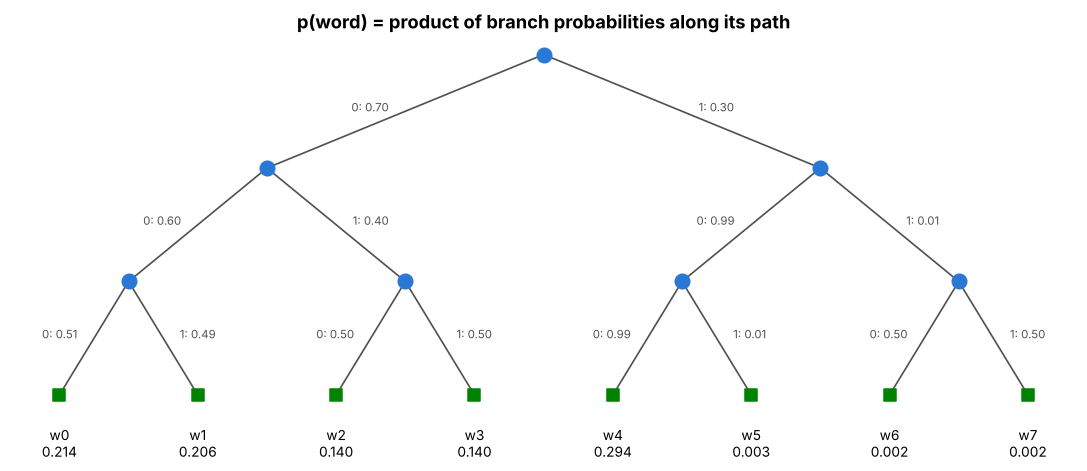

In [5]:
fig, ax = plt.subplots(figsize=(10, 4.4))
draw_tree(ax, toy_children, 8, toy_words, p_left=toy_p_left, leaf_text=[f"{p:.3f}" for p in p_toy])
ax.set_title("p(word) = product of branch probabilities along its path")
plt.tight_layout(); plt.show()

---
## 3 · Which tree? Huffman coding 🗜️

Any binary tree with $n$ leaves works, but the cost of one word is its path length $L(w)$. A **balanced** tree gives every word $\approx\log_2n$. word2vec uses a **Huffman tree** (the notes' choice): frequent words get **short** paths, rare words long ones, so the *average* cost over the data is as small as possible.

**Huffman's algorithm:**
1. Start with every word as a separate tree, weighted by its frequency $f(w)$.
2. Repeatedly take the **two lightest** trees, join them under a new inner node, and give it the sum of their weights.
3. Stop when one tree is left – after exactly $n-1$ joins, i.e. $n-1$ inner nodes.

A min-heap (`heapq`) always gives us the two lightest trees. The lighter one goes left (bit 0).

In [6]:
def build_huffman(freq):
    """children[node] = (left, right). Leaves 0..n-1, inner nodes n..2n-2, root = 2n-2."""
    n_leaves = len(freq)
    heap = [(float(f), i) for i, f in enumerate(freq)]      # (weight, node id)
    heapq.heapify(heap)
    children = np.full((2 * n_leaves - 1, 2), -1)
    next_id = n_leaves
    while len(heap) > 1:
        w1, a = heapq.heappop(heap)                          # lightest
        w2, b = heapq.heappop(heap)                          # second lightest
        children[next_id] = (a, b)
        heapq.heappush(heap, (w1 + w2, next_id))
        next_id += 1
    return children

**Paths and codes.** Walk down from the root and record, for every leaf, the inner nodes passed, the bits, and the signs $s_j=+1$ (left) / $-1$ (right). Inner node ids $n..2n-2$ are shifted by $-n$ so that they index the rows $0..n-2$ of $U$.

In [7]:
def tree_paths(children, n_leaves):
    """For every leaf: (row indices of the inner nodes on its path, signs, code string)."""
    paths = {}
    stack = [(len(children) - 1, [], [], "")]
    while stack:
        node, nodes, signs, code = stack.pop()
        if node < n_leaves:
            paths[node] = (np.array(nodes, dtype=int) - n_leaves, np.array(signs), code)
            continue
        left, right = children[node]
        stack.append((left, nodes + [node], signs + [1.0], code + "0"))
        stack.append((right, nodes + [node], signs + [-1.0], code + "1"))
    return paths

### 3.1 · A small Huffman example
Six words with made-up frequencies. The most frequent word gets the shortest code.

In [8]:
small_words = ["the", "like", "king", "mango", "river", "crown"]
small_freq = np.array([45, 20, 13, 12, 6, 4])
small_children = build_huffman(small_freq)
small_paths = tree_paths(small_children, len(small_words))
for i, w in enumerate(small_words):
    print(f"  {w:<6} f = {small_freq[i]:>2}   code = {small_paths[i][2]:<5}  length {len(small_paths[i][2])}")
avg = sum(small_freq[i] * len(small_paths[i][2]) for i in range(6)) / small_freq.sum()
print(f"\n  average code length = {avg:.2f} bits   (balanced tree: log2(6) = {np.log2(6):.2f}, rounded up to 3)")

  the    f = 45   code = 0      length 1
  like   f = 20   code = 111    length 3
  king   f = 13   code = 110    length 3
  mango  f = 12   code = 101    length 3
  river  f =  6   code = 1001   length 4
  crown  f =  4   code = 1000   length 4

  average code length = 2.20 bits   (balanced tree: log2(6) = 2.58, rounded up to 3)


📊 **Plot:** the Huffman tree for these six words with each word's code. Following the bits from the root spells the code (the notes' *w₁: 00, w₅: 10, w₄: 0111* are exactly such codes).

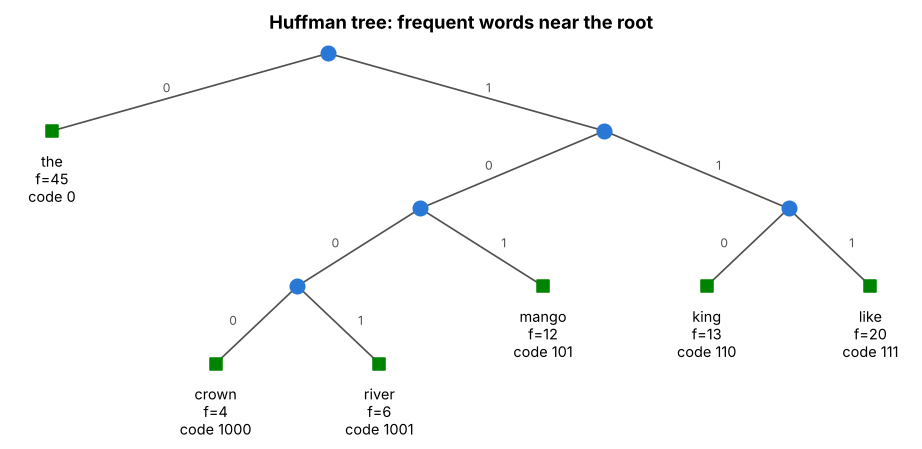

In [9]:
fig, ax = plt.subplots(figsize=(8.5, 4.2))
draw_tree(ax, small_children, 6, small_words, leaf_text=[f"f={small_freq[i]}\ncode {small_paths[i][2]}" for i in range(6)], fs=9.5)
ax.set_title("Huffman tree: frequent words near the root")
plt.tight_layout(); plt.show()

---
## 4 · The Huffman tree of our corpus 📚

### 4.1 · The data
Same corpus and skip-gram pairs as notebooks 06–07. The frequency $f(w)$ is how often $w$ appears as a **target** – those are the leaves the model must reach.

In [10]:
PEOPLE = {   # word: (status, gender, age)
    "king": ("royal", "male", "adult"),     "queen": ("royal", "female", "adult"),
    "prince": ("royal", "male", "young"),   "princess": ("royal", "female", "young"),
    "man": ("common", "male", "adult"),     "woman": ("common", "female", "adult"),
    "boy": ("common", "male", "young"),     "girl": ("common", "female", "young"),
}
POOLS = {    # context words that describe each attribute
    "royal": ["palace", "crown", "throne", "kingdom"],  "common": ["village", "farm", "market", "cottage"],
    "male": ["he", "his", "him", "beard"],              "female": ["she", "her", "hers", "dress"],
    "adult": ["works", "office", "married", "tax"],     "young": ["plays", "school", "toys", "small"],
}
THINGS = {   # topic: (topic words, context words)
    "fruit": (["mango", "apple", "banana", "grape"], ["eat", "sweet", "ripe", "tree", "juicy"]),
    "drink": (["water", "tea", "coffee", "milk"], ["drink", "cup", "hot", "glass", "pour"]),
    "money": (["loan", "money", "interest", "account"], ["bank", "pay", "rupees", "save", "cash"]),
    "river": (["river", "stream", "fish", "boat"], ["bank", "flow", "swim", "shore", "wet"]),
}


def make_corpus(n_sentences=1500, seed=0):
    """Generate a toy corpus whose words have hidden 'meanings' (attributes) we know in advance."""
    rng = np.random.default_rng(seed)
    sentences = []
    for _ in range(n_sentences):
        if rng.random() < 0.55:                                   # a sentence about a person
            word = str(rng.choice(list(PEOPLE)))
            context = [str(rng.choice(POOLS[a])) for a in PEOPLE[word]]   # one word per attribute
            rng.shuffle(context)
            sentences.append(["the", word] + context)
        else:                                                     # a sentence about a thing
            words, ctx = THINGS[rng.choice(list(THINGS))]
            sentences.append(["i", "like", "the", str(rng.choice(words))] + [str(c) for c in rng.choice(ctx, 2, replace=False)])
    sentences += [["i", "like", "going", "to", "my", "old", "house"]] * 20   # the example from the notes
    return sentences

**Vocabulary, pairs and target frequencies:**

In [11]:
def skipgram_pairs(sentences, index, window=3):
    """All (center, context) index pairs within `window` positions."""
    pairs = []
    for s in sentences:
        ids = [index[w] for w in s]
        for pos, c in enumerate(ids):
            for ctx_pos in range(max(0, pos - window), min(len(ids), pos + window + 1)):
                if ctx_pos != pos:
                    pairs.append((c, ids[ctx_pos]))
    return np.array(pairs)

sentences = make_corpus()
vocab = sorted({w for s in sentences for w in s})
index = {w: i for i, w in enumerate(vocab)}
n = len(vocab)
pairs = skipgram_pairs(sentences, index)
N = len(pairs)
freq = np.bincount(pairs[:, 1], minlength=n)
print(f"n = {n} words, N = {N:,} pairs")

n = 75 words, N = 31,734 pairs


### 4.2 · Build the tree

In [12]:
children = build_huffman(freq)
paths = tree_paths(children, n)
code_len = np.array([len(paths[w][2]) for w in range(n)])
avg_len = (freq * code_len).sum() / freq.sum()
entropy = -(freq / freq.sum() * np.log2(freq / freq.sum())).sum()
print(f"inner nodes          : {np.sum(children[:, 0] >= 0)}  (= n − 1 = {n - 1})")
print(f"code length          : min {code_len.min()}, max {code_len.max()}")
print(f"average (per pair)   : {avg_len:.2f} nodes")
print(f"log2 n               : {np.log2(n):.2f}")
print(f"entropy of f (bits)  : {entropy:.2f}   ← Huffman's average is always within 1 bit of this")
for w in ["the", "like", "king", "mango", "going"]:
    print(f"  {w:<6} f = {freq[index[w]]:>5}   code = {paths[index[w]][2]}")

inner nodes          : 74  (= n − 1 = 74)
code length          : min 3, max 9
average (per pair)   : 5.47 nodes
log2 n               : 6.23
entropy of f (bits)  : 5.42   ← Huffman's average is always within 1 bit of this
  the    f =  5878   code = 111
  like   f =  2836   code = 1101
  king   f =   380   code = 001100
  mango  f =   195   code = 0100001
  going  f =   100   code = 01011100


📊 **Plot:** code length against frequency. Frequent words sit near the root (2–3 decisions), rare ones deeper. The frequency-weighted average is below $\log_2n$.

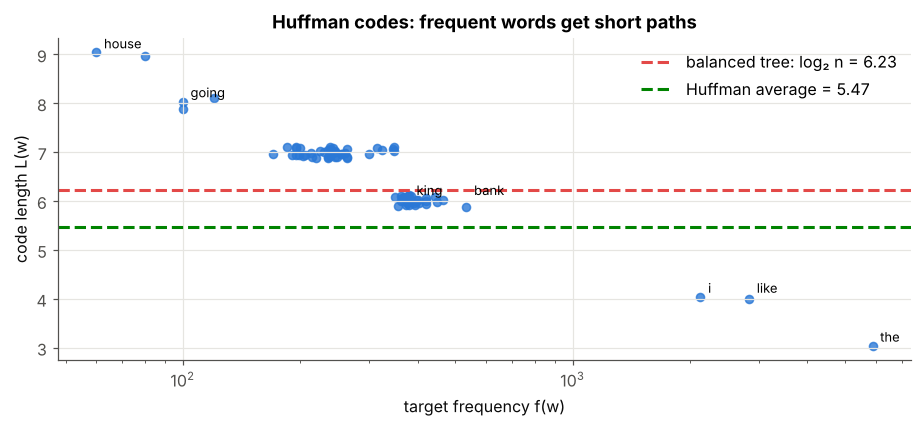

In [13]:
fig, ax = plt.subplots(figsize=(8.5, 4))
ax.scatter(freq, code_len + np.random.default_rng(0).uniform(-0.12, 0.12, n), color=C["blue"], s=28, alpha=0.8)
for w in ["the", "like", "i", "bank", "king", "going", "house"]:
    ax.annotate(w, (freq[index[w]], code_len[index[w]]), textcoords="offset points", xytext=(5, 4), fontsize=8.5)
ax.axhline(np.log2(n), color=C["red"], ls="--", label=f"balanced tree: log₂ n = {np.log2(n):.2f}")
ax.axhline(avg_len, color=C["green"], ls="--", label=f"Huffman average = {avg_len:.2f}")
ax.set_xscale("log"); ax.set_xlabel("target frequency f(w)"); ax.set_ylabel("code length L(w)"); ax.legend()
ax.set_title("Huffman codes: frequent words get short paths")
plt.tight_layout(); plt.show()

### 4.3 · Does it scale like $\log n$?
Real vocabularies follow roughly **Zipf's law**: the $r$-th most frequent word has $f\propto1/r$. Build Huffman trees for Zipf vocabularies up to $n=10^5$ and compare the average path length with $\log_2n$ and with $n$ (the full softmax's cost).

In [14]:
sizes = [100, 1_000, 10_000, 100_000]
zipf_avg = []
for nz in sizes:
    fz = 1.0 / np.arange(1, nz + 1)
    ch = build_huffman(fz)
    pz = tree_paths(ch, nz)
    lens = np.array([len(pz[i][2]) for i in range(nz)])          # in leaf order, to match fz
    zipf_avg.append((fz * lens).sum() / fz.sum())
    print(f"n = {nz:>7,}:  average path = {zipf_avg[-1]:5.2f}    log2 n = {np.log2(nz):5.2f}")

n =     100:  average path =  5.35    log2 n =  6.64
n =   1,000:  average path =  7.52    log2 n =  9.97
n =  10,000:  average path =  9.56    log2 n = 13.29
n = 100,000:  average path = 11.53    log2 n = 16.61


📊 **Plot:** nodes evaluated per training pair. Full softmax: $n$. Hierarchical softmax: at most $\approx\log_2n$, and with Huffman codes on Zipf-distributed words even less – about 12 for $10^5$ words.

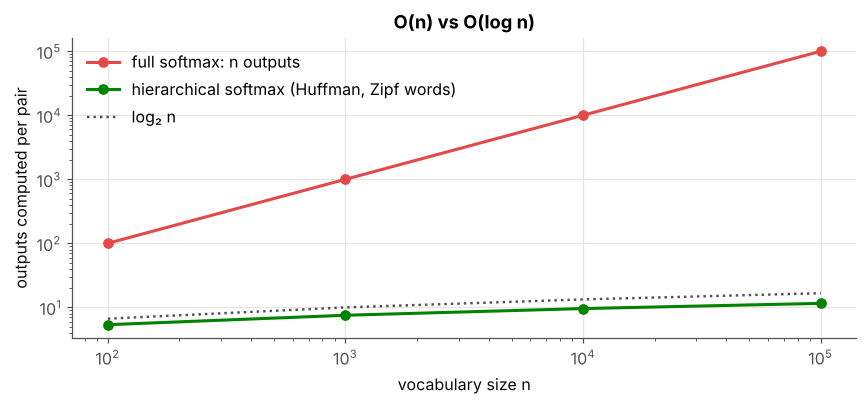

In [15]:
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(sizes, sizes, "o-", color=C["red"], lw=2, label="full softmax: n outputs")
ax.plot(sizes, zipf_avg, "o-", color=C["green"], lw=2, label="hierarchical softmax (Huffman, Zipf words)")
ax.plot(sizes, np.log2(sizes), ":", color=C["muted"], lw=1.6, label="log₂ n")
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlabel("vocabulary size n"); ax.set_ylabel("outputs computed per pair")
ax.legend(); ax.set_title("O(n) vs O(log n)")
plt.tight_layout(); plt.show()

---
## 5 · Training: the gradient along one path ✍️

For a pair $(c,o)$ the error is again $E=-\log p(o\mid h)$ – a **real** probability now – and the log turns the product into a sum:

$$E=-\sum_{j\in\text{path}(o)}\log\sigma\big(s_j\ u_j\cdot h\big)$$

Each term is a logistic regression (notebook 07, section 2) with label $\ell_j=1$ if the path goes left at $j$ and $\ell_j=0$ if right. So, with $a_j=u_j\cdot h$:

$$\frac{\partial E}{\partial a_j}=\sigma(a_j)-\ell_j\qquad\Rightarrow\qquad\boxed{\Delta u_j=-\eta\ \big(\sigma(u_j\cdot h)-\ell_j\big)\ h}\quad\text{for } j\in\text{path}(o)$$

$$\boxed{\Delta v_c=-\eta\sum_{j\in\text{path}(o)}\big(\sigma(u_j\cdot h)-\ell_j\big)\ u_j}$$

Only the $L(o)$ inner nodes on the path change – $\approx\log_2n$ rows of $U$ instead of $n$.

### 5.1 · The model
$V$ is unchanged ($d\times n$, the word vectors). $U$ has $n-1$ rows, one per **inner node**. The parameter count is $d\ n+d\ (n-1)\approx2dn$ – the same as before.

In [16]:
class SkipGramHS:
    """Skip-gram word2vec with a Huffman-tree hierarchical softmax."""

    def __init__(self, n, d, children, seed=0):
        rng = np.random.default_rng(seed)
        self.n, self.d, self.children = n, d, children
        self.paths = tree_paths(children, n)
        self.V = rng.normal(0, 0.1, (d, n))             # word vectors (columns)
        self.U = rng.normal(0, 0.1, (n - 1, d))         # one row per INNER NODE
        self.steps = 0
        self.values_updated = 0

### 5.2 · $p(w\mid h)$ for one word, and for all words
`word_probability` multiplies along one path ($L(w)$ dot products). `all_probabilities` uses the top-down pass of section 2.1 ($n-1$ dot products) – used only for checking and for inference.

In [17]:
def sigmoid(a):
    return 1.0 / (1.0 + np.exp(-a))


def word_probability(self, c, w):
    nodes, signs, _ = self.paths[w]
    return np.prod(sigmoid(signs * (self.U[nodes] @ self.V[:, c])))


def all_probabilities(self, c):
    p_left = sigmoid(self.U @ self.V[:, c])               # P(left) at every inner node
    return leaf_probabilities(self.children, self.n, lambda node: p_left[node - self.n])

SkipGramHS.word_probability = word_probability
SkipGramHS.all_probabilities = all_probabilities

### 5.3 · One SGD step
| code | formula |
|---|---|
| `nodes, signs = paths[o]` | the inner nodes on the path to $o$, and $s_j$ |
| `a = U[nodes] @ h` | $a_j=u_j\cdot h$ (only $L(o)$ dot products) |
| `labels = (signs > 0)` | $\ell_j$: 1 = left, 0 = right |
| `g = sigmoid(a) - labels` | $\partial E/\partial a_j$ |
| `U[nodes] -= eta * np.outer(g, h)` | $\Delta u_j$ on the path only |
| `V[:, c] -= eta * g @ U[nodes]` | $\Delta v_c$ |

`E` is computed as $-\sum\log\sigma(s_ja_j)$. (A path never visits the same node twice, so plain fancy indexing is safe here.)

In [18]:
def sgd_step(self, c, o, eta):
    h = self.V[:, c].copy()
    nodes, signs, _ = self.paths[o]
    a = self.U[nodes] @ h
    E = -np.log(sigmoid(signs * a)).sum()
    g = sigmoid(a) - (signs > 0)                    # dE/da_j = σ(a_j) − ℓ_j
    grad_h = g @ self.U[nodes]
    self.U[nodes] -= eta * np.outer(g, h)           # L(o) rows of U
    self.V[:, c] -= eta * grad_h                    # one column of V
    self.steps += 1
    self.values_updated += (len(nodes) + 1) * self.d
    return E

SkipGramHS.sgd_step = sgd_step

### 5.4 · Checks before training
1. The leaf probabilities of an untrained model sum to 1.
2. `word_probability` (one path) agrees with `all_probabilities` (whole tree).
3. The gradient of `sgd_step` matches a numerical gradient.

In [19]:
model = SkipGramHS(n, 10, children, seed=0)
p_all = model.all_probabilities(index["king"])
print("Σ_w p(w | king)               =", round(p_all.sum(), 10))
print("p(queen | king), one path     =", round(model.word_probability(index["king"], index["queen"]), 6))
print("p(queen | king), whole tree   =", round(p_all[index["queen"]], 6))

Σ_w p(w | king)               = 1.0
p(queen | king), one path     = 0.01497
p(queen | king), whole tree   = 0.01497


**Gradient check** – run `sgd_step` with $\eta=1$ on a copy, so the change in the parameters *is* minus the gradient:

In [20]:
import copy
c0, o0 = index["king"], index["crown"]
m = copy.deepcopy(model); m.sgd_step(c0, o0, eta=1.0)
grad_U, grad_V = model.U - m.U, model.V - m.V             # = dE/dU, dE/dV

def E_of(mod):
    return -np.log(mod.word_probability(c0, o0))

num_U, num_V = np.zeros_like(model.U), np.zeros_like(model.V)
for P, G in [(model.U, num_U), (model.V, num_V)]:
    for idx in np.ndindex(P.shape):
        old = P[idx]
        P[idx] = old + 1e-6; ep = E_of(model)
        P[idx] = old - 1e-6; em = E_of(model)
        P[idx] = old; G[idx] = (ep - em) / 2e-6
rel = lambda a, b: np.linalg.norm(a - b) / (np.linalg.norm(a) + np.linalg.norm(b))
print(f"dE/dU relative error: {rel(grad_U, num_U):.1e}   rows changed: {np.flatnonzero(np.abs(grad_U).sum(1)).size} of {n - 1} (path length {len(paths[o0][2])})")
print(f"dE/dV relative error: {rel(grad_V, num_V):.1e}")

dE/dU relative error: 2.4e-09   rows changed: 7 of 74 (path length 7)
dE/dV relative error: 8.8e-10


### 5.5 · One epoch

In [21]:
def train_epoch(self, pairs, eta, rng, log_every=2000):
    curve, running = [], []
    for c, o in pairs[rng.permutation(len(pairs))]:
        running.append(self.sgd_step(c, o, eta))
        if len(running) == log_every:
            curve.append(np.mean(running)); running = []
    return curve


def vectors(self):
    return self.V / np.linalg.norm(self.V, axis=0, keepdims=True)

SkipGramHS.train_epoch = train_epoch
SkipGramHS.vectors = vectors

---
## 6 · Training 🏋️

Same settings as notebook 06: $d=10$, $\eta=0.05$, 5 epochs. The error is the same quantity as in notebook 06, $-\log p(o\mid c)$, so we can compare it with the same start $\log n$ and floor $H(O\mid C)$.

In [22]:
counts = np.zeros((n, n)); np.add.at(counts, (pairs[:, 0], pairs[:, 1]), 1)
P_true = counts / counts.sum(axis=1, keepdims=True)
H_floor = -np.mean(np.log(P_true[pairs[:, 0], pairs[:, 1]]))

d, eta, epochs = 10, 0.05, 5
model = SkipGramHS(n, d, children, seed=0)
rng = np.random.default_rng(1)
curve, epoch_times = [], []
for ep in range(epochs):
    t0 = time.perf_counter()
    curve += model.train_epoch(pairs, eta, rng)
    epoch_times.append(time.perf_counter() - t0)
    print(f"epoch {ep + 1}:  mean loss = {curve[-1]:.3f}   time = {epoch_times[-1]:.2f} s")
print(f"\nvalues updated per step: {model.values_updated / model.steps:.1f}  (full softmax: {n * d + d})")

epoch 1:  mean loss = 3.002   time = 0.88 s
epoch 2:  mean loss = 2.961   time = 0.72 s
epoch 3:  mean loss = 2.949   time = 0.71 s
epoch 4:  mean loss = 2.927   time = 0.77 s
epoch 5:  mean loss = 2.929   time = 0.74 s

values updated per step: 64.7  (full softmax: 760)


📊 **Plot:** the loss falls from $\log n$ towards the same floor as the full softmax.

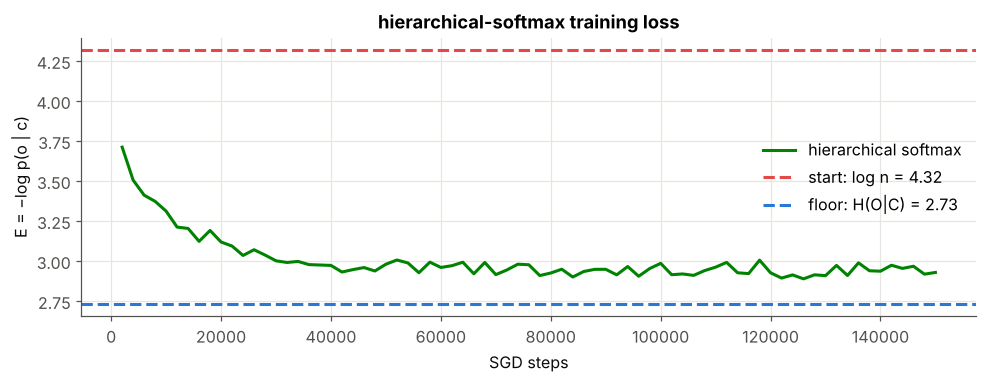

In [23]:
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.plot(np.arange(1, len(curve) + 1) * 2000, curve, color=C["green"], lw=2, label="hierarchical softmax")
ax.axhline(np.log(n), color=C["red"], ls="--", label=f"start: log n = {np.log(n):.2f}")
ax.axhline(H_floor, color=C["blue"], ls="--", label=f"floor: H(O|C) = {H_floor:.2f}")
ax.set_xlabel("SGD steps"); ax.set_ylabel("E = −log p(o | c)"); ax.legend()
ax.set_title("hierarchical-softmax training loss")
plt.tight_layout(); plt.show()

### 6.1 · Quality of the vectors

In [24]:
W = model.vectors()

def neighbours(word, k=5):
    sims = W.T @ W[:, index[word]]
    best = [i for i in np.argsort(-sims) if i != index[word]][:k]
    return [(vocab[i], round(float(sims[i]), 2)) for i in best]


def analogy(a, b, c, k=3):
    q = W[:, index[a]] - W[:, index[b]] + W[:, index[c]]
    sims = W.T @ (q / np.linalg.norm(q))
    for w in (a, b, c):
        sims[index[w]] = -np.inf
    return [vocab[i] for i in np.argsort(-sims)[:k]]

for w in ["king", "mango", "loan", "river", "bank"]:
    print(f"{w:>6} → {neighbours(w)}")
print()
for a, b, c, want in [("king", "man", "woman", "queen"), ("prince", "boy", "girl", "princess"), ("queen", "woman", "man", "king")]:
    got = analogy(a, b, c)
    print(f"{a} − {b} + {c} = {got}   {'✅' if got[0] == want else '❌'} (expected {want})")

  king → [('man', 0.67), ('prince', 0.64), ('queen', 0.58), ('beard', 0.47), ('princess', 0.45)]
 mango → [('apple', 0.99), ('grape', 0.99), ('banana', 0.98), ('sweet', 0.75), ('tree', 0.72)]
  loan → [('interest', 0.98), ('money', 0.97), ('account', 0.97), ('going', 0.74), ('save', 0.68)]
 river → [('stream', 0.99), ('fish', 0.99), ('boat', 0.99), ('swim', 0.7), ('wet', 0.65)]
  bank → [('cash', 0.87), ('save', 0.79), ('flow', 0.76), ('pay', 0.75), ('rupees', 0.72)]

king − man + woman = ['queen', 'princess', 'swim']   ✅ (expected queen)
prince − boy + girl = ['princess', 'dress', 'queen']   ✅ (expected princess)
queen − woman + man = ['king', 'prince', 'tax']   ✅ (expected king)


And unlike negative sampling, the outputs are a real distribution:

In [25]:
for w in ["king", "mango"]:
    p = model.all_probabilities(index[w])
    top = np.argsort(-p)[:5]
    print(f"{w:>6}: Σ p = {p.sum():.6f}   top: {[(vocab[i], round(float(p[i]), 3)) for i in top]}")

  king: Σ p = 1.000000   top: [('the', 0.202), ('works', 0.114), ('his', 0.108), ('kingdom', 0.089), ('palace', 0.081)]
 mango: Σ p = 1.000000   top: [('i', 0.164), ('like', 0.163), ('the', 0.156), ('eat', 0.12), ('tree', 0.114)]


---
## 7 · Inference: which word is most likely? 🔍

Training needs $p(o\mid h)$ for **one known** word – one path, cheap. At inference time we often want the **most likely** word, $\arg\max_wp(w\mid h)$, without computing all $n$ leaves. Three strategies (notes page 20):

| method | idea | exact? | cost |
|---|---|---|---|
| **greedy** | at every node take the more likely branch | no | one path: $\approx\log n$ (worst $O(n)$ in a degenerate tree) |
| **beam search** | keep the $B$ most likely partial paths at each depth | no, but better as $B$ grows | $\approx B\log n$, **chosen in advance** |
| **branch and bound** | always expand the most likely open node; stop when the best open node is a leaf | **yes** | depends on $h$ – **budget not controllable** |

Branch and bound is exact because probabilities can only **shrink** going down (each factor is $\le1$): once the best open item is a leaf, no other branch can beat it.

All three only need a function `p_left(node)`, so they work for the toy tree and the trained model alike. Each counts how many inner nodes it **evaluated** (sigmoid computations).

### 7.1 · Greedy

In [26]:
def greedy(children, n_leaves, p_left):
    get = p_left if callable(p_left) else p_left.__getitem__
    node, p, evals = len(children) - 1, 1.0, 0
    while node >= n_leaves:
        pl = get(node); evals += 1
        node, p = (children[node][0], p * pl) if pl >= 0.5 else (children[node][1], p * (1 - pl))
    return node, p, evals

### 7.2 · Beam search
Each round, expand every inner node in the beam into its two children, then keep the $B$ most probable items (leaves included). Stop when the beam holds only leaves. $B=1$ is greedy.

In [27]:
def beam_search(children, n_leaves, p_left, B=3):
    get = p_left if callable(p_left) else p_left.__getitem__
    beam, evals = [(1.0, len(children) - 1)], 0
    while any(node >= n_leaves for _, node in beam):
        candidates = []
        for p, node in beam:
            if node < n_leaves:
                candidates.append((p, node)); continue
            pl = get(node); evals += 1
            candidates += [(p * pl, children[node][0]), (p * (1 - pl), children[node][1])]
        beam = sorted(candidates, reverse=True)[:B]
    p, node = beam[0]
    return node, p, evals

### 7.3 · Branch and bound (best-first)
A priority queue of open items ordered by path probability. Pop the best; if it is a leaf, it is the answer; otherwise evaluate it and push both children.

In [28]:
def branch_and_bound(children, n_leaves, p_left):
    get = p_left if callable(p_left) else p_left.__getitem__
    heap, evals = [(-1.0, len(children) - 1)], 0
    while True:
        neg_p, node = heapq.heappop(heap)
        if node < n_leaves:
            return node, -neg_p, evals
        pl = get(node); evals += 1
        heapq.heappush(heap, (neg_p * pl, children[node][0]))
        heapq.heappush(heap, (neg_p * (1 - pl), children[node][1]))

### 7.4 · The notes' example: greedy fails

In [29]:
for name, fn in [("greedy", lambda: greedy(toy_children, 8, toy_p_left)),
                 ("beam B=2", lambda: beam_search(toy_children, 8, toy_p_left, B=2)),
                 ("branch & bound", lambda: branch_and_bound(toy_children, 8, toy_p_left))]:
    leaf, p, ev = fn()
    print(f"{name:<15} → {toy_words[leaf]}  p = {p:.3f}   nodes evaluated = {ev}")
print(f"{'true best':<15} → {toy_words[np.argmax(p_toy)]}  p = {p_toy.max():.3f}")

greedy          → w0  p = 0.214   nodes evaluated = 3
beam B=2        → w4  p = 0.294   nodes evaluated = 5
branch & bound  → w4  p = 0.294   nodes evaluated = 5
true best       → w4  p = 0.294


Greedy goes left at the root ($0.7>0.3$) and can never come back: it finds $0.7\times0.6\times0.51=0.214$, while the right branch hides $0.3\times0.99\times0.99=0.294$.

📊 **Plot:** the path greedy takes (left) and the best path (right).

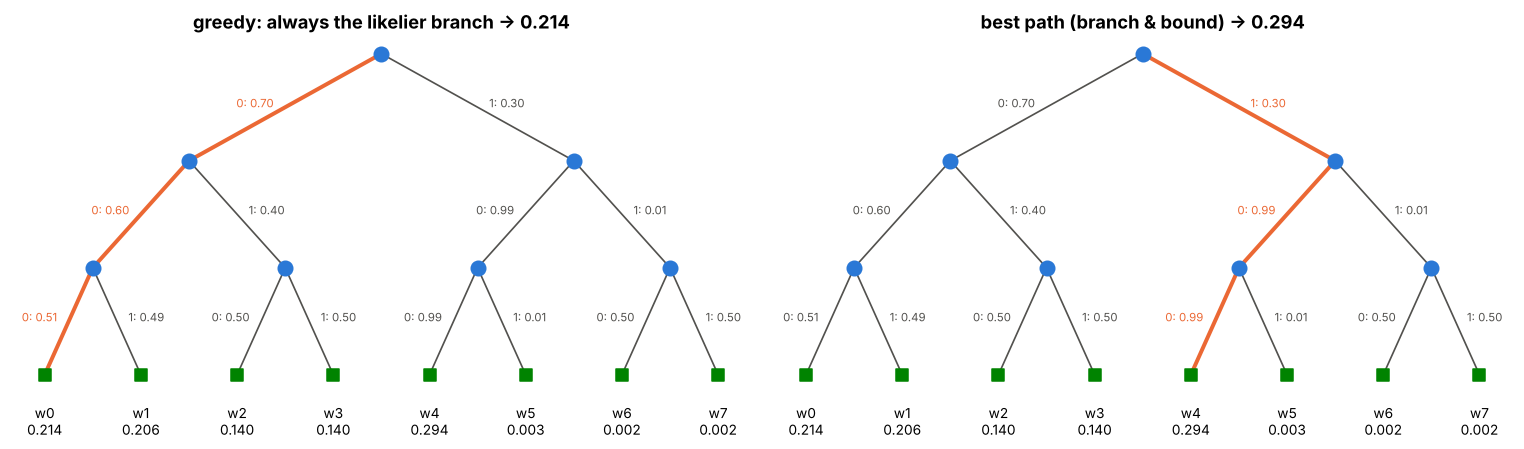

In [30]:
fig, axs = plt.subplots(1, 2, figsize=(14, 4.2))
for ax, leaf, title in [(axs[0], greedy(toy_children, 8, toy_p_left)[0], "greedy: always the likelier branch → 0.214"),
                        (axs[1], int(np.argmax(p_toy)), "best path (branch & bound) → 0.294")]:
    hl, node = {leaf}, leaf
    parent = {int(ch): i for i in range(8, 15) for ch in toy_children[i]}
    while node in parent:
        node = parent[node]; hl.add(node)
    draw_tree(ax, toy_children, 8, toy_words, p_left=toy_p_left, highlight=hl, leaf_text=[f"{p:.3f}" for p in p_toy])
    ax.set_title(title)
plt.tight_layout(); plt.show()

### 7.5 · On the trained model
For every word $c$ as input, find the most likely context word with each method and compare with the exact answer from `all_probabilities` (which evaluates all $n-1=74$ nodes).

In [31]:
def p_left_fn(model, c):
    p = sigmoid(model.U @ model.V[:, c])
    return lambda node: p[node - model.n]

methods = {"greedy": lambda f: greedy(children, n, f),
           "beam B=2": lambda f: beam_search(children, n, f, B=2),
           "beam B=4": lambda f: beam_search(children, n, f, B=4),
           "branch & bound": lambda f: branch_and_bound(children, n, f)}
results = {name: {"correct": 0, "evals": [], "ratio": []} for name in methods}
for c in range(n):
    exact = model.all_probabilities(c)
    best = int(np.argmax(exact))
    f = p_left_fn(model, c)
    for name, fn in methods.items():
        leaf, p, ev = fn(f)
        results[name]["correct"] += int(leaf == best)
        results[name]["evals"].append(ev)
        results[name]["ratio"].append(p / exact[best])
for name, r in results.items():
    print(f"{name:<15} exact answer for {r['correct']:>2}/{n} words   avg nodes evaluated {np.mean(r['evals']):5.1f} (max {max(r['evals']):>2})   "
          f"avg p found / best p = {np.mean(r['ratio']):.3f}")
print(f"{'exhaustive':<15} exact answer for {n}/{n} words   nodes evaluated {n - 1}")

greedy          exact answer for 30/75 words   avg nodes evaluated   5.1 (max  9)   avg p found / best p = 0.723
beam B=2        exact answer for 57/75 words   avg nodes evaluated   9.3 (max 16)   avg p found / best p = 0.914
beam B=4        exact answer for 75/75 words   avg nodes evaluated  16.5 (max 23)   avg p found / best p = 1.000
branch & bound  exact answer for 75/75 words   avg nodes evaluated   6.4 (max 13)   avg p found / best p = 1.000
exhaustive      exact answer for 75/75 words   nodes evaluated 74


📊 **Plot:** the trade-off – nodes evaluated (cost) vs how often the exact best word is found.

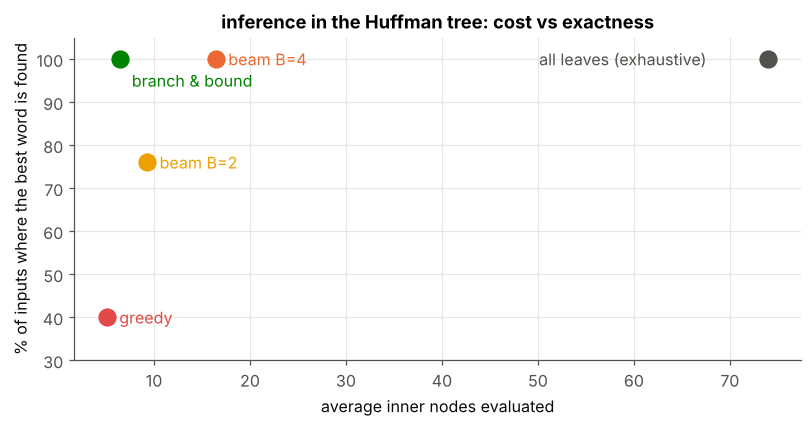

In [32]:
fig, ax = plt.subplots(figsize=(7.5, 4))
cols = [C["red"], C["yellow"], C["orange"], C["green"]]
for (name, r), col in zip(results.items(), cols):
    ax.scatter(np.mean(r["evals"]), 100 * r["correct"] / n, s=120, color=col, zorder=3)
    ax.annotate(name, (np.mean(r["evals"]), 100 * r["correct"] / n), textcoords="offset points", xytext=(8, -18) if name == "branch & bound" else (8, -4), color=col)
ax.scatter(n - 1, 100, s=120, color=C["muted"], zorder=3)
ax.annotate("all leaves (exhaustive)", (n - 1, 100), textcoords="offset points", xytext=(-150, -4), color=C["muted"])
ax.set_xlabel("average inner nodes evaluated"); ax.set_ylabel("% of inputs where the best word is found")
ax.set_ylim(min(100 * r["correct"] / n for r in results.values()) - 10, 105)
ax.set_title("inference in the Huffman tree: cost vs exactness")
plt.tight_layout(); plt.show()

What we see:
* **greedy** is cheapest (one path) but often misses the best word – the notes' failure case is common in practice;
* **beam search** gets better as $B$ grows; its cost is fixed by $B$ *before* we start, which is why the notes recommend it when there is a **budget at inference time**;
* **branch and bound** is always exact. Here it is even cheap on average, because the trained model is usually confident near the root – but its cost depends on the input (compare the average and the max), and for an uncertain $h$ it can explore much of the tree. Its budget is **not controllable**.

---
## 8 · Summary 📌

| | full softmax | negative sampling | hierarchical softmax |
|---|---|---|---|
| output layer | $n$ scores + softmax | $k+1$ sigmoids | $L(o)\approx\log_2n$ sigmoids along a path |
| rows of $U$ | $n$ (one per word) | $n$ (one per word) | $n-1$ (one per **inner node**) |
| updated per step | $n$ rows | $k+1$ rows | $L(o)$ rows |
| $\sum_wp(w)=1$? | yes | no | **yes** |
| most-likely word | compute all $n$ | – | greedy / beam / branch & bound |

### ✍️ Try it yourself
1. Replace the Huffman tree by a **balanced** tree. How do the average path length and the training time per epoch change?
2. Build a tree that groups *similar* words under the same subtree (e.g. all fruits). Does training get easier?
3. Make a "degenerate" Huffman tree with frequencies $1,2,4,8,\dots$. What is the longest path? Why is greedy then $O(n)$ in the worst case?
4. Count how many nodes branch and bound evaluates for *the* vs for *going*. Why the difference?

**Next →** `09 - Comparing Training Variants`: all three methods side by side.